In [1]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def calculate_sphere_flux(
    n_theta: int = 300,
    n_phi: int = 600
) -> float:
    """
    计算向量场 F=(x,y,z) 穿过单位球面的净通量。

    参数：
        n_theta: 极角 theta 方向的网格数量
        n_phi: 方位角 phi 方向的网格数量

    返回：
        flux: 数值计算得到的闭合曲面通量
    """

    # 每一个小网格对应的角度宽度
    d_theta = np.pi / n_theta
    d_phi = 2.0 * np.pi / n_phi

    # 使用每个网格的中点，数值积分通常更准确
    theta = (
        np.arange(n_theta) + 0.5
    ) * d_theta

    phi = (
        np.arange(n_phi) + 0.5
    ) * d_phi

    # 生成 theta-phi 二维参数网格
    theta_grid, phi_grid = np.meshgrid(
        theta,
        phi,
        indexing="ij"
    )

    # 单位球面的参数方程
    x = (
        np.sin(theta_grid)
        * np.cos(phi_grid)
    )

    y = (
        np.sin(theta_grid)
        * np.sin(phi_grid)
    )

    z = np.cos(theta_grid)

    # 向量场 F=(x,y,z)
    field_x = x
    field_y = y
    field_z = z

    # 单位球面的外法向量 n=(x,y,z)
    normal_x = x
    normal_y = y
    normal_z = z

    # 点乘 F·n
    field_dot_normal = (
        field_x * normal_x
        + field_y * normal_y
        + field_z * normal_z
    )

    # 单位球面面积元：
    # dS = sin(theta) dtheta dphi
    area_factor = np.sin(theta_grid)

    # 数值曲面积分
    flux = np.sum(
        field_dot_normal * area_factor
    ) * d_theta * d_phi

    return float(flux)

def plot_sphere_and_vectors() -> None:
    """画单位球面和球面外法向量。"""

    theta = np.linspace(0.0, np.pi, 120)
    phi = np.linspace(0.0, 2.0 * np.pi, 240)

    theta_grid, phi_grid = np.meshgrid(
        theta,
        phi,
        indexing="ij"
    )

    x = (
        np.sin(theta_grid)
        * np.cos(phi_grid)
    )

    y = (
        np.sin(theta_grid)
        * np.sin(phi_grid)
    )

    z = np.cos(theta_grid)

    fig = plt.figure(figsize=(8, 7))

    ax = fig.add_subplot(
        111,
        projection="3d"
    )

    # 绘制球面
    ax.plot_surface(
        x,
        y,
        z,
        alpha=0.25,
        linewidth=0
    )

    # 不需要在每个点都画箭头，
    # 否则箭头太密集
    step_theta = 12
    step_phi = 24

    x_sample = x[
        ::step_theta,
        ::step_phi
    ]

    y_sample = y[
        ::step_theta,
        ::step_phi
    ]

    z_sample = z[
        ::step_theta,
        ::step_phi
    ]

    # 单位球上的外法向量就是 (x,y,z)
    normal_x = x_sample
    normal_y = y_sample
    normal_z = z_sample

    ax.quiver(
        x_sample,
        y_sample,
        z_sample,
        normal_x,
        normal_y,
        normal_z,
        length=0.35,
        normalize=True
    )

    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("z")

    # 保证三个方向使用相同比例
    ax.set_box_aspect((1, 1, 1))

    ax.set_title(
        "Unit Sphere and Outward Normal Vectors"
    )

    plt.tight_layout()
    plt.show()

Numerical flux: 12.566428
Exact flux:     12.566371
Absolute error: 5.741921e-05


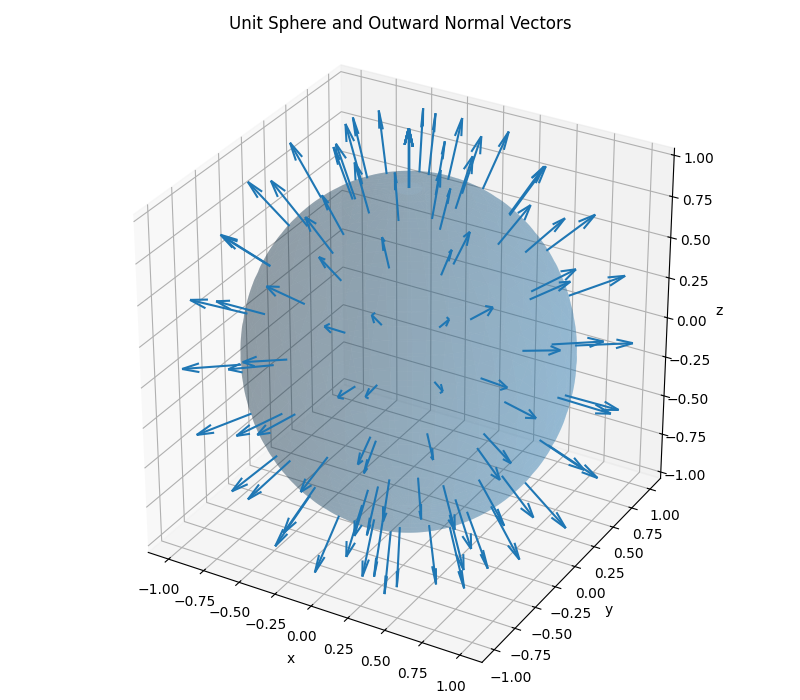

In [3]:
numerical_flux = calculate_sphere_flux()
exact_flux = 4.0 * np.pi

print(
    f"Numerical flux: {numerical_flux:.6f}"
)

print(
    f"Exact flux:     {exact_flux:.6f}"
)

print(
    f"Absolute error: "
    f"{abs(numerical_flux - exact_flux):.6e}"
)

plot_sphere_and_vectors()

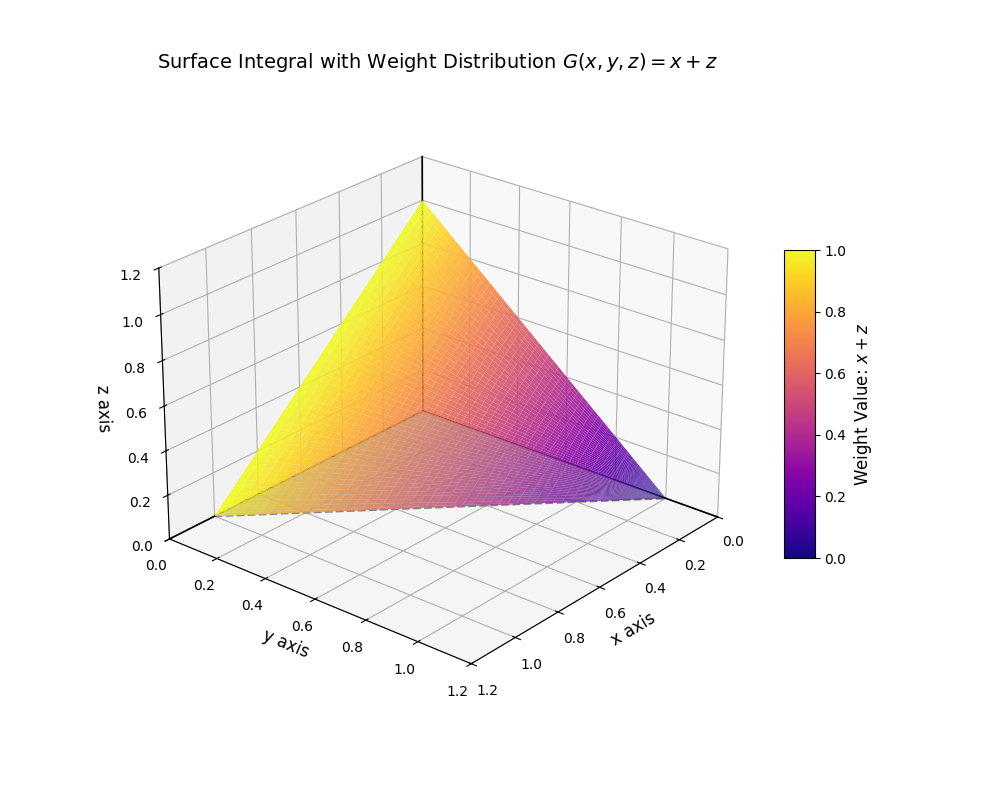

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm

# 1. 初始化 3D 图形
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# 2. 为了画出完美的三角形边界，我们使用参数方程映射
# 将一个正方形 (u,v) 映射到三角形 (X,Y)
u = np.linspace(0, 1, 100)
v = np.linspace(0, 1, 100)
U, V = np.meshgrid(u, v)

# 参数映射: 保证 X + Y <= 1
X = U * (1 - V)
Y = V
Z = 1 - X - Y  # 曲面方程

# 3. 计算每个点上的“权重”（即被积函数 x + z）
Weight = X + Z

# 4. 根据权重生成颜色 (这里使用 'plasma' 暖色调)
# 因为 Weight 的范围刚好在 [0, 1] 之间，可以直接映射到 colormap
colors = cm.plasma(Weight)

# 5. 绘制曲面，用 facecolors 参数把权重颜色贴到曲面上
surf = ax.plot_surface(X, Y, Z, facecolors=colors, shade=False, alpha=0.9, edgecolor='none')

# 6. 在底部画出投影区域 R (作为参考阴影)
# 投影区域的 Z 坐标设为 0
ax.plot_surface(X, Y, np.zeros_like(Z), color='lightgray', alpha=0.3, edgecolor='none')
ax.plot([1, 0], [0, 1], [0, 0], color='gray', linestyle='--') # 投影的边界线

# 7. 绘制坐标轴
ax.plot([0, 1.2], [0, 0], [0, 0], color='black', linewidth=1.2) # x轴
ax.plot([0, 0], [0, 1.2], [0, 0], color='black', linewidth=1.2) # y轴
ax.plot([0, 0], [0, 0], [0, 1.2], color='black', linewidth=1.2) # z轴

# 8. 添加一个颜色条 (Colorbar) 来解释颜色的含义
m = cm.ScalarMappable(cmap=cm.plasma, norm=plt.Normalize(vmin=0, vmax=1))
m.set_array([])
cbar = plt.colorbar(m, ax=ax, shrink=0.5, aspect=10)
cbar.set_label('Weight Value: $x + z$', fontsize=12)

# 9. 设置坐标轴标签和范围
ax.set_xlim([0, 1.2])
ax.set_ylim([0, 1.2])
ax.set_zlim([0, 1.2])
ax.set_xlabel('x axis', fontsize=12)
ax.set_ylabel('y axis', fontsize=12)
ax.set_zlabel('z axis', fontsize=12)
ax.set_title("Surface Integral with Weight Distribution $G(x,y,z) = x+z$", fontsize=14, pad=20)

# 10. 调整视角
ax.view_init(elev=25, azim=40)

plt.show()